# Stirling engine

Stirling engine is well-known type of heat engine based on cycling a working substance through isothermal expansion, isochoric cooling, isothermal compression and isochoric heating. While absorbing heat from one reservoir and transferring heat to another, it extracts useful work during the expansion phase.

In this notebook, we will investigate a system undergoing similar thermodynamic cycles at the microscale. Specifically, the system consists of a brownian particle confined inside optical tweezers (modeled as a harmonic potential) while in contact with a controlled thermal bath.

## Stirling cycle in optical tweezers

Consider optical tweezers with a controlled stiffness $k(t)$ and a controlled environment temperature $T(t)$. The harmonic potential inside the trap is given by
$$U(t,x) = \frac{1}{2}k_t x^2.$$
The stiffness $k_t$ can be intuitively interpreted as the inverse of the volume $V$ in a conventional Stirling engine, as it dictates the spatial confinement and available variance of particle with a given energy.

The stochastic equivalent of the Stirling cycles proceeds through the following four strokes:
1. **Isochoric cooling:** The stiffness $k(t)$ is held constant at its maximum value $k_1$, while the temperature $T(t)$ decreases from $T_1$ (hot) to $T_0$ (cold).
2. **Isothermic compression:** The stiffness $k(t)$ increases from $k_0$ to $k_1$ (tightening the trap and compressing the particle distribution), while the temperature is held constant at $T(t) = T_0$.
3. **Isochoric heating:** The stiffness is held constant at $k(t) = k_0$, while the temperature $T(t)$ rises from $T_0$ to $T_1$.
4. **Isothermic expansion:** The stiffness $k(t)$ decreases from $k_1$ to $k_0$ (widening the trap and allowing the spatial distribution to expand), while the temperature is held constant at $T(t) = T_1$.

We will use the following curves:

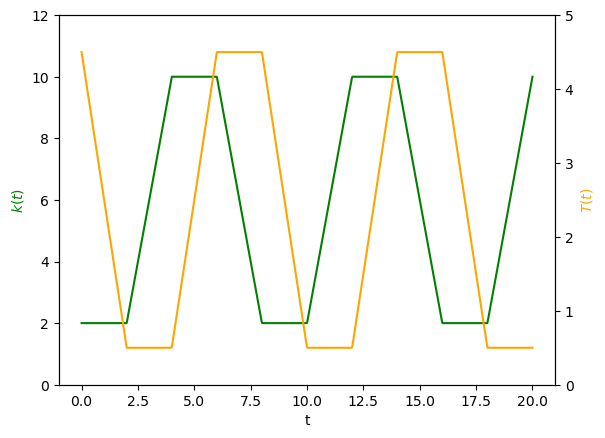

In [1]:
import matplotlib.pyplot as plt
import numpy as np

t0 = 2

def k(t):
    rem = t % t0
    phase = (t // t0) % 4
    
    conditions = [
        phase == 0,
        phase == 1,
        phase == 2,
        phase == 3
    ]

    choices = [
        2,
        2 + 4 * rem,
        10,
        10 - 4 * rem
    ]

    return np.select(conditions, choices, default = np.nan)

def T(t):
    rem = t % t0
    phase = (t // t0) % 4

    conditions = [
        phase == 0,
        phase == 1,
        phase == 2,
        phase == 3
    ]

    choices = [
        4.5 - 2 * rem,
        0.5,
        0.5 + 2 * rem,
        4.5
    ]

    return np.select(conditions, choices, default = np.nan)

t = np.linspace(0,20,800)
res = np.empty_like(t)
res2 = np.empty_like(t)
for i in range(len(t)):
    res[i] = k(t[i])
    res2[i] = T(t[i])

fig, ax1 = plt.subplots()
ax2 = ax1.twinx()
ax1.set(ylim = [0,12]), ax1.set_ylabel(r'$k(t)$',color="green"), ax1.set_xlabel(r"t")
ax2.set(ylim = [0,5.0]), ax2.set_ylabel(r'$T(t)$',color="orange")
ax1.plot(t,res, color="green")
ax2.plot(t,res2, color="orange")

We calculate single solution using `LSolver`:

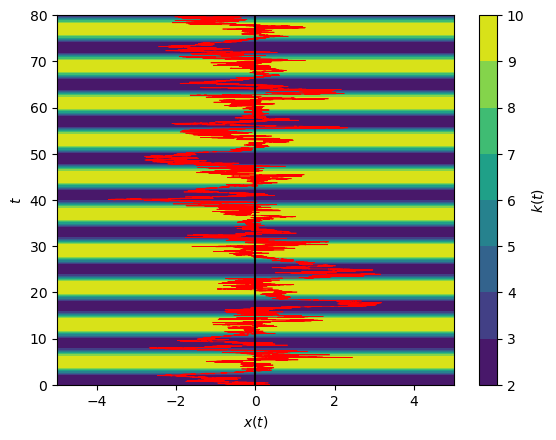

In [2]:
from LSolver import SimulationConfig, overdamped

def beta(t):
    return 1/T(t)
gma = 2.0

cfg = SimulationConfig(
    gamma = gma,
    Fx_func = lambda t,x,y: -k(t)*x,
    Tx_func = lambda t,x,y: T(t),
    t_max = 80.0,
    dt = 0.001
)

fig, ax = plt.subplots(1,1)

[X, Y] = np.meshgrid(np.linspace(-5,5,150),np.linspace(0,80,150))
Z = k(Y)

cs = ax.contourf(X,Y,Z)

rng = np.random.default_rng(seed = 42)

data = overdamped(cfg, rng = rng)[0]

ax.set(xlabel = r"$x(t)$", ylabel = r"$t$")
ax.plot(data, cfg.t_array, color = "red", linewidth=0.5)
ax.plot([0,0],[0,80], color="black")
fig.colorbar(cs, label = r"$k(t)$")

Differentiating the potential energy of a particle with trajectory $x(t)$ gives us:
$$\dot U(t) = \frac{1}{2}\dot k(t) x(t)^2 + k(t) \dot x(t) x(t) = dW + dQ,$$
where the considered work is done by controlling of the stiffness (the first term), while the heat is generated by random fluctuations of the brownian particle (the second term). In terms of differentials
$$dU(t) = \frac{1}{2} x(t)^2 dk(t) + k(t) x(t) dx(t).$$
This formula is useful, because it shows us how to evaluate work and heat in our discretized model:
$$\Delta W(t) = \frac{1}{2}x(t)^2 \Delta k(t),$$
$$\Delta Q(t) = k(t) x(t) \Delta x(t).$$
Note that the work $W(t)$ is actually evaluated from the perspective of the brownian particle, i.e. negative $W(t)$ means that work $-W(t)$ was transferred to the reservoirs. For the simulated trajectory:

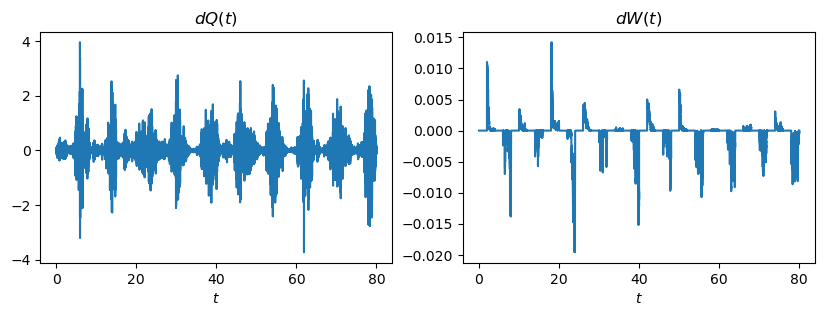

In [3]:
dx = np.diff(data)
dk = np.diff(k(cfg.t_array))

x_mid = 0.5 * (data[:-1] + data[1:])
k_mid = 0.5 * (k(cfg.t_array)[:-1] + k(cfg.t_array)[1:])
t = 0.5 * (cfg.t_array[:-1] + cfg.t_array[1:])

dW = 0.5 * (x_mid**2) * dk
dQ = k_mid * x_mid * dx

fig, [ax1, ax2] = plt.subplots(1,2,figsize=(10,3))
ax1.set(xlabel = r"$t$", title = r"$dQ(t)$")
ax2.set(xlabel = r"$t$", title = r"$dW(t)$")
ax1.plot(t, dQ)
ax2.plot(t, dW)

For the entropy:
$$\Delta S(t) = \frac{\Delta Q(t)}{T(t)}$$

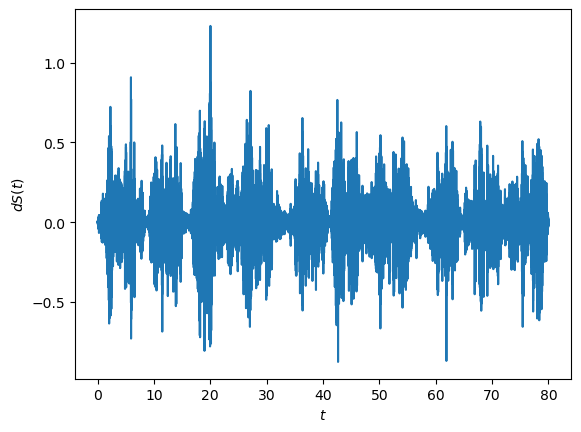

In [4]:
T_mid = 0.5 * (T(cfg.t_array)[:-1] + T(cfg.t_array)[1:])
dS = dQ / T_mid

fig, ax = plt.subplots(1,1)
ax.set(xlabel = r"$t$", ylabel = r"$dS(t)$")
ax.plot(t, dS)

## Measurements of statistical ensemble

Now consider whole ensemble of systems like the above one. In such ensemble, we can calculate fluctuations, deviation and other statistical properties of this Stirling-like process. We begin with mean values of work and heat:

100%|████████████████████████████████████████████████████████████████████████████████| 500/500 [02:57<00:00,  2.81it/s]


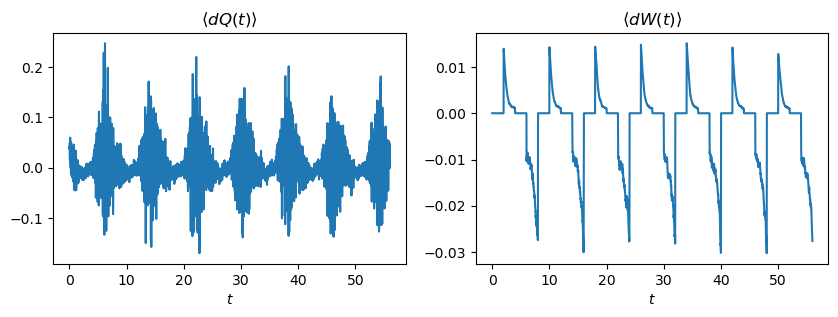

In [5]:
from tqdm import tqdm

N = 500

cfg = SimulationConfig(
    gamma = gma,
    Fx_func = lambda t,x,y: -k(t)*x,
    Tx_func = lambda t,x,y: T(t),
    t_max = 56.0,
    dt = 0.01
)

data = np.empty(shape=(N,len(cfg.t_array)))
rng = np.random.default_rng(seed = 42)

for m in tqdm(range(N)):
    data[m] = overdamped(cfg, rng=rng)[0]

k_mid = 0.5 * (k(cfg.t_array)[:-1] + k(cfg.t_array)[1:])
t = 0.5 * (cfg.t_array[:-1] + cfg.t_array[1:])
x_mid = np.empty(shape=(N,len(k_mid)))

dx = np.empty(shape=(N, len(t)))
dW = np.empty_like(dx)
dQ = np.empty_like(dx)
dk = np.diff(k(cfg.t_array))
for i in range(len(dx)):
    dx[i] = np.diff(data[i])
    x_mid[i] = 0.5 * (data[i,:-1] + data[i,1:])

for i in range(len(dx)):
    dW[i] = 0.5 * (x_mid[i]**2) * dk
    dQ[i] = k_mid * x_mid[i] * dx[i]

dWavg = np.mean(dW, axis = 0)
dQavg = np.mean(dQ, axis = 0)

fig, [ax1, ax2] = plt.subplots(1,2,figsize=(10,3))
ax1.set(xlabel = r"$t$", title = r"$\langle dQ(t)\rangle$")
ax2.set(xlabel = r"$t$", title = r"$\langle dW(t)\rangle$")
ax1.plot(t, dQavg)
ax2.plot(t, dWavg)

Now plot the distribution of work per cycle $W_T$ and entropy per cycle $\Sigma_T$. Note that we will change the sign of work and entropy, which corresponds to measurement from the perspective of the reservoir/environment.

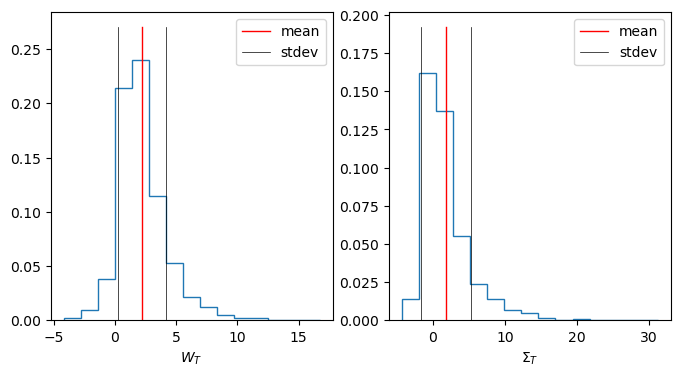

In [6]:
period = 8.0
N_cycles = int(max(cfg.t_array) / period)
steps = len(cfg.t_array) // N_cycles

data_cycles = data.reshape(N, N_cycles, steps)
stable_cycles = data_cycles[:,2:,:].reshape(-1, steps)
cycle_t = cfg.t_array[:steps]

t = 0.5 * (cycle_t[:-1] + cycle_t[1:])
k_mid = 0.5 * (k(cycle_t)[:-1] + k(cycle_t)[1:])
x_mid = np.empty(shape=(N*(N_cycles-2),len(k_mid)))
T_mid = 0.5 * (T(cycle_t)[:-1] + T(cycle_t)[1:])
dx = np.empty_like(x_mid)
dk = np.diff(k(cycle_t))
for i in range(len(dx)):
    dx[i] = np.diff(stable_cycles[i])
    x_mid[i] = 0.5 * (stable_cycles[i,:-1] + stable_cycles[i,1:])

W = np.zeros(shape=(N*(N_cycles - 2)))
Q = np.zeros_like(W)

W = - np.sum(0.5*(x_mid **2)*dk[np.newaxis, :], axis = 1)
Q = np.sum(k_mid[np.newaxis, :] * x_mid * dx, axis = 1)

# Entropy from heat dissipated into the reservoir
S = - np.sum(k_mid[np.newaxis, :] * x_mid * dx / T_mid[np.newaxis, :], axis = 1)

fig, [ax1, ax2] = plt.subplots(1,2, figsize=(8,4))

counts, bins = np.histogram(W, density = True, bins = 15)
ax1.stairs(counts, bins)
ax1.set(xlabel=r"$W_T$")
Wmean = np.mean(W)
Wstd = np.std(W)
ax1.plot([Wmean,Wmean],[0,max(counts)+0.03],color = "red", linewidth = 1.0, label="mean")
ax1.plot([Wmean - Wstd, Wmean - Wstd],[0, max(counts)+0.03], color = "black", linewidth = 0.5, label="stdev")
ax1.plot([Wmean + Wstd, Wmean + Wstd],[0, max(counts)+0.03], color = "black", linewidth = 0.5)
ax1.legend(loc="best")

counts, bins = np.histogram(S, density = True, bins = 15)
Smean = np.mean(S)
Sstd = np.std(S)
ax2.stairs(counts, bins)
ax2.set(xlabel=r"$\Sigma_T$")
ax2.plot([Smean,Smean],[0,max(counts)+0.03],color = "red", linewidth = 1.0, label="mean")
ax2.plot([Smean - Sstd, Smean - Sstd],[0, max(counts)+0.03], color = "black", linewidth = 0.5,label="stdev")
ax2.plot([Smean + Sstd, Smean + Sstd],[0, max(counts)+0.03], color = "black", linewidth = 0.5)
ax2.legend(loc="best")

We can test the energy conservation (1st thermodynamics law):

In [7]:
print("Energy balance throughout one cycle: <ΔU> = <Q> - <W> = {0:.5f}".format(np.mean(Q) - np.mean(W)))
print("Work: <W> = {0:.5f}, Heat: <Q> = {1:.5f}".format(np.mean(W), np.mean(Q)))

Energy balance throughout one cycle: <ΔU> = <Q> - <W> = 0.04074
Work: <W> = 2.20499, Heat: <Q> = 2.24574


### Thermodynamic uncertainty relation (TUR)

We can check whether the TUR is satisfied for this system
$$\frac{\text{Var }W_T}{\langle W_T \rangle^2} \geq \frac{2 k_B}{\langle \Sigma_T \rangle}.$$
The means and variation in this inequality are taken as integral over one cycle, while doing the statistics over all cycles in our ensemble. We can calculate the value of $\langle \Sigma_T \rangle (\text{Var }W_T)/\langle W_T \rangle^2$ and check whether it is larger then $2k_B$, or in our case $2$ (since $k_B = 1$).

In [8]:
TUR = np.var(W) * np.mean(S) / (np.mean(W))**2
print(TUR)

1.4419269650405862


It seems like the TUR is not satisfied in this case, which is expected, since the system is externally driven, and the work is not a steady-state current. Original TUR were stated for non-equilibrium, time-independent steady state heat engines.